In [1]:
import pandas as pd

In [3]:
data = pd.read_csv(r"C:\Users\HP\Desktop\DJIFlightRecord_2024-10-17_[13-51-44].csv")

C:\Users\HP\AppData\Local\Temp\ipykernel_8352\4145076455.py:1: DtypeWarning: Columns (41) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(r"C:\Users\HP\Desktop\DJIFlightRecord_2024-10-17_[13-51-44].csv")


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7374 entries, 0 to 7373
Columns: 192 entries, CUSTOM.date [local] to APP.warning
dtypes: bool(58), float64(83), int64(16), object(35)
memory usage: 7.9+ MB


In [6]:
data.describe()

,OSD.flyTime [s],OSD.latitude,OSD.longitude,OSD.height [ft],OSD.heightMax [ft],OSD.vpsHeight [ft],OSD.altitude [ft],OSD.mileage [ft],OSD.hSpeed [MPH],OSD.hSpeedMax [MPH],...,DETAILS.photoNum,DETAILS.videoTime [s],DETAILS.appType,SERIAL.camera,SERIAL.gimbal,SERIAL.rc,SERIAL.battery,APPGPS.latitude,APPGPS.longitude,APPGPS.accuracy
count,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,7374.000000,...,7374.0,7374.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,746.946311,26.442364,74.725704,757.431909,877.504475,80.536127,3001.392324,29585.149227,24.520332,31.820642,...,0.0,4212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,430.743088,0.007283,0.023562,367.797472,170.127382,15.151991,367.814792,18449.214853,14.121833,8.189276,...,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.100000,26.429143,74.695778,-502.600000,0.000000,0.000000,1741.000000,0.000000,0.000000,0.000000,...,0.0,4212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,373.950000,26.436139,74.702490,908.400000,909.400000,83.600000,3152.000000,13207.350000,10.692947,34.019878,...,0.0,4212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,746.100000,26.444258,74.723016,908.700000,913.700000,83.600000,3153.000000,29743.550000,33.314638,34.019878,...,0.0,4212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1120.450000,26.447341,74.746035,916.000000,922.900000,83.600000,3160.000000,47775.650000,33.431590,34.019878,...,0.0,4212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,1492.800000,26.455948,74.769508,929.100000,929.100000,83.600000,3173.000000,53904.700000,34.019878,34.019878,...,0.0,4212.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
data.columns

Index(['CUSTOM.date [local]', 'CUSTOM.updateTime [local]', 'OSD.flyTime',
       'OSD.flyTime [s]', 'OSD.latitude', 'OSD.longitude', 'OSD.height [ft]',
       'OSD.heightMax [ft]', 'OSD.vpsHeight [ft]', 'OSD.altitude [ft]',
       ...
       'SERIAL.flightController', 'SERIAL.camera', 'SERIAL.gimbal',
       'SERIAL.rc', 'SERIAL.battery', 'APPGPS.latitude', 'APPGPS.longitude',
       'APPGPS.accuracy', 'APP.tip', 'APP.warning'],
      dtype='object', length=192)

In [8]:
data=data.select_dtypes(exclude=[object])

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7374 entries, 0 to 7373
Columns: 157 entries, OSD.flyTime [s] to APPGPS.accuracy
dtypes: bool(58), float64(83), int64(16)
memory usage: 6.0 MB


In [10]:
nan_count=data.isnull().sum()

In [11]:
nan_count.sum()

222644

In [12]:
import missingno as ms

ModuleNotFoundError: No module named 'missingno'

In [13]:
!pip install missingno

In [14]:
import missingno as ms

<AxesSubplot:>

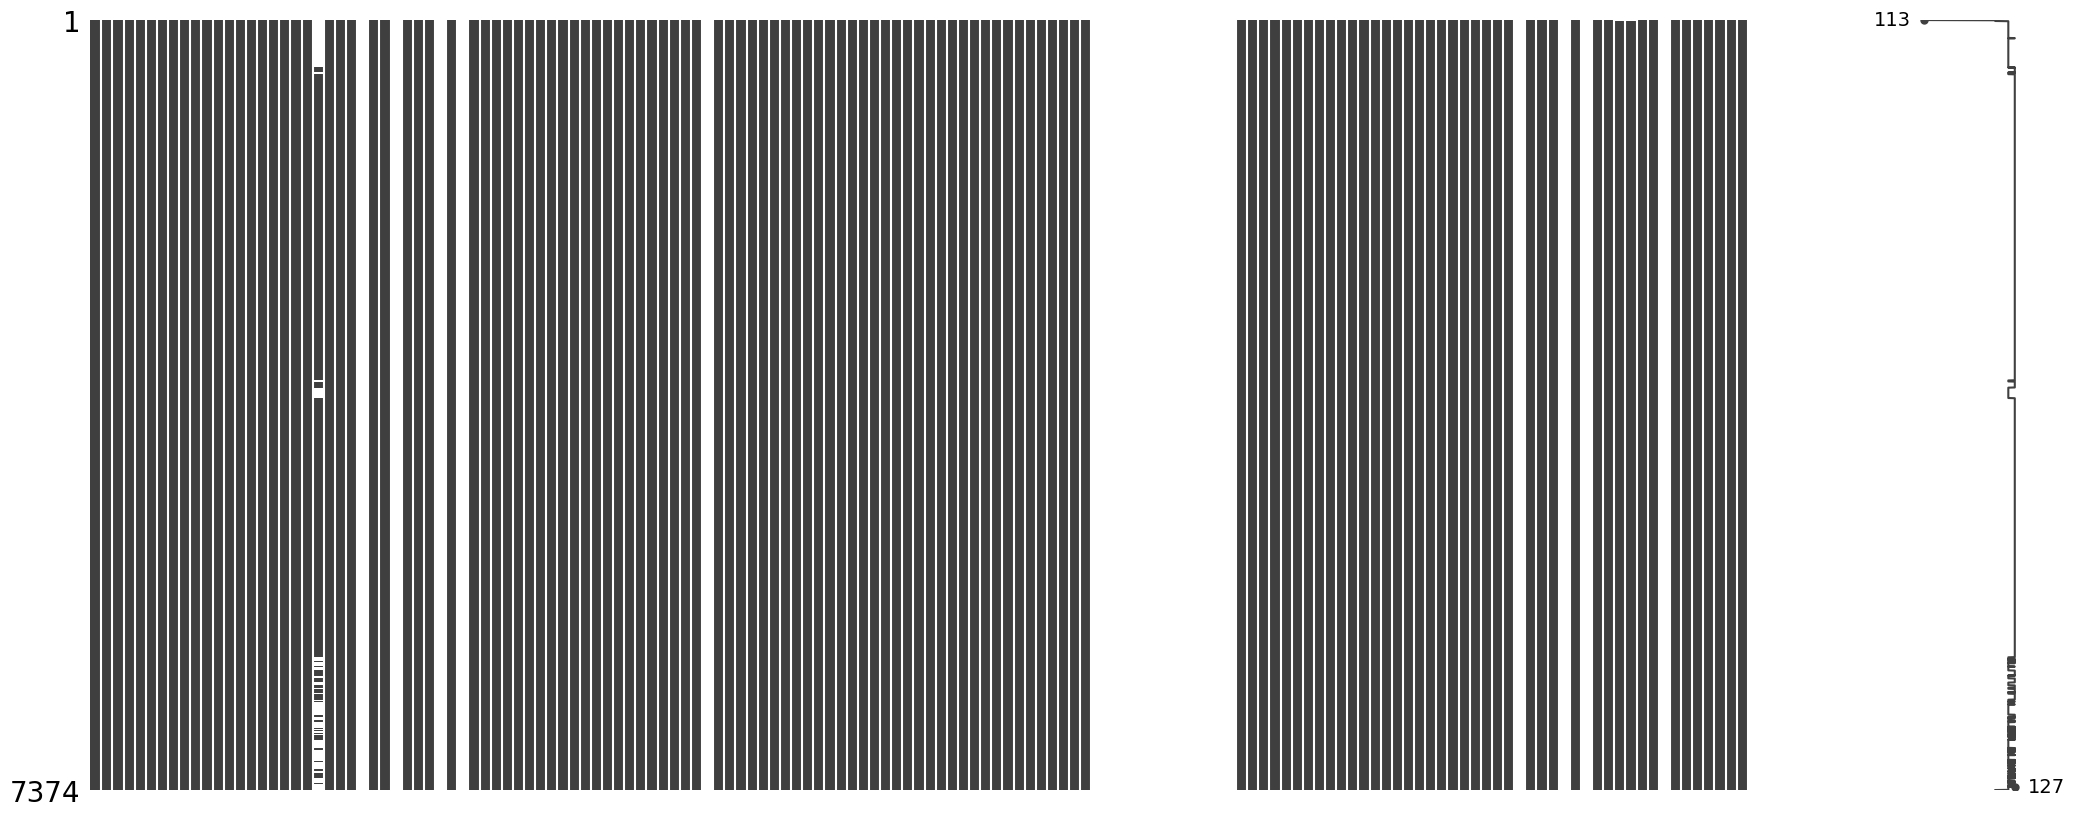

In [15]:
ms.matrix(data)

In [16]:
# Identify and drop columns with 100% null values
columns_with_all_nulls = nan_count[nan_count == len(data)].index

In [17]:
print(columns_with_all_nulls)

Index(['OSD.nonGPSCause', 'OSD.goHomeStatus', 'OSD.motorStartFailedCause',
       'OSD.imuInitFailReason', 'CAMERA.filename', 'BATTERY.usefulTime [s]',
       'BATTERY.goHomeTime [s]', 'BATTERY.landTime [s]',
       'BATTERY.goHomeBattery', 'BATTERY.landBattery', 'BATTERY.safeFlyRadius',
       'BATTERY.volumeConsume', 'BATTERY.status', 'BATTERY.goHomeCountdown',
       'BATTERY.lowWarning', 'BATTERY.lowWarningGoHome',
       'BATTERY.seriousLowWarning', 'BATTERY.seriousLowWarningLanding',
       'HOME.compassCalibrationState', 'HOME.iocMode', 'HOME.courseLockAngle',
       'RECOVER.appType', 'DETAILS.appType', 'SERIAL.camera', 'SERIAL.gimbal',
       'SERIAL.rc', 'SERIAL.battery', 'APPGPS.latitude', 'APPGPS.longitude',
       'APPGPS.accuracy'],
      dtype='object')


In [18]:
threshold = len(data) / 2

In [19]:
print(threshold)

3687.0


In [20]:
columns_with_many_nulls = nan_count[nan_count > threshold].index

In [21]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7374 entries, 0 to 7373
Columns: 157 entries, OSD.flyTime [s] to APPGPS.accuracy
dtypes: bool(58), float64(83), int64(16)
memory usage: 6.0 MB
None


In [22]:
nan_count.sum()

222644

In [23]:
df=data

In [24]:
columns_with_all_nulls = df.columns[df.isnull().mean() == 1.0]

# Print the columns with 100% null values
print("Columns with 100% null values:")
print(columns_with_all_nulls)

# Count the number of columns with 100% null values
count_all_nulls = len(columns_with_all_nulls)
print("\nNumber of columns with 100% null values:")
print(count_all_nulls)

Columns with 100% null values:
Index(['OSD.nonGPSCause', 'OSD.goHomeStatus', 'OSD.motorStartFailedCause',
       'OSD.imuInitFailReason', 'CAMERA.filename', 'BATTERY.usefulTime [s]',
       'BATTERY.goHomeTime [s]', 'BATTERY.landTime [s]',
       'BATTERY.goHomeBattery', 'BATTERY.landBattery', 'BATTERY.safeFlyRadius',
       'BATTERY.volumeConsume', 'BATTERY.status', 'BATTERY.goHomeCountdown',
       'BATTERY.lowWarning', 'BATTERY.lowWarningGoHome',
       'BATTERY.seriousLowWarning', 'BATTERY.seriousLowWarningLanding',
       'HOME.compassCalibrationState', 'HOME.iocMode', 'HOME.courseLockAngle',
       'RECOVER.appType', 'DETAILS.appType', 'SERIAL.camera', 'SERIAL.gimbal',
       'SERIAL.rc', 'SERIAL.battery', 'APPGPS.latitude', 'APPGPS.longitude',
       'APPGPS.accuracy'],
      dtype='object')

Number of columns with 100% null values:
30


In [25]:
df=df.drop(['OSD.nonGPSCause', 'OSD.goHomeStatus', 'OSD.motorStartFailedCause',
       'OSD.imuInitFailReason', 'CAMERA.filename', 'BATTERY.usefulTime [s]',
       'BATTERY.goHomeTime [s]', 'BATTERY.landTime [s]',
       'BATTERY.goHomeBattery', 'BATTERY.landBattery', 'BATTERY.safeFlyRadius',
       'BATTERY.volumeConsume', 'BATTERY.status', 'BATTERY.goHomeCountdown',
       'BATTERY.lowWarning', 'BATTERY.lowWarningGoHome',
       'BATTERY.seriousLowWarning', 'BATTERY.seriousLowWarningLanding',
       'HOME.compassCalibrationState', 'HOME.iocMode', 'HOME.courseLockAngle',
       'RECOVER.appType', 'DETAILS.appType', 'SERIAL.camera', 'SERIAL.gimbal',
       'SERIAL.rc', 'SERIAL.battery', 'APPGPS.latitude', 'APPGPS.longitude',
       'APPGPS.accuracy'],axis=1)

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7374 entries, 0 to 7373
Columns: 127 entries, OSD.flyTime [s] to DETAILS.videoTime [s]
dtypes: bool(58), float64(53), int64(16)
memory usage: 4.3 MB


In [27]:
count_all_nulls = len(columns_with_all_nulls)

In [28]:
print(count_all_nulls)

30


In [29]:
nan_counts = df.isnull().sum()

In [30]:
print(nan_counts)

OSD.flyTime [s]                     0
OSD.latitude                        0
OSD.longitude                       0
OSD.height [ft]                     0
OSD.heightMax [ft]                  0
                                   ..
DETAILS.maxHeight [ft]              0
DETAILS.maxHorizontalSpeed [MPH]    0
DETAILS.maxVerticalSpeed [MPH]      0
DETAILS.photoNum                    0
DETAILS.videoTime [s]               0
Length: 127, dtype: int64



Total Missing Values in Dataset: 1424


<AxesSubplot:>

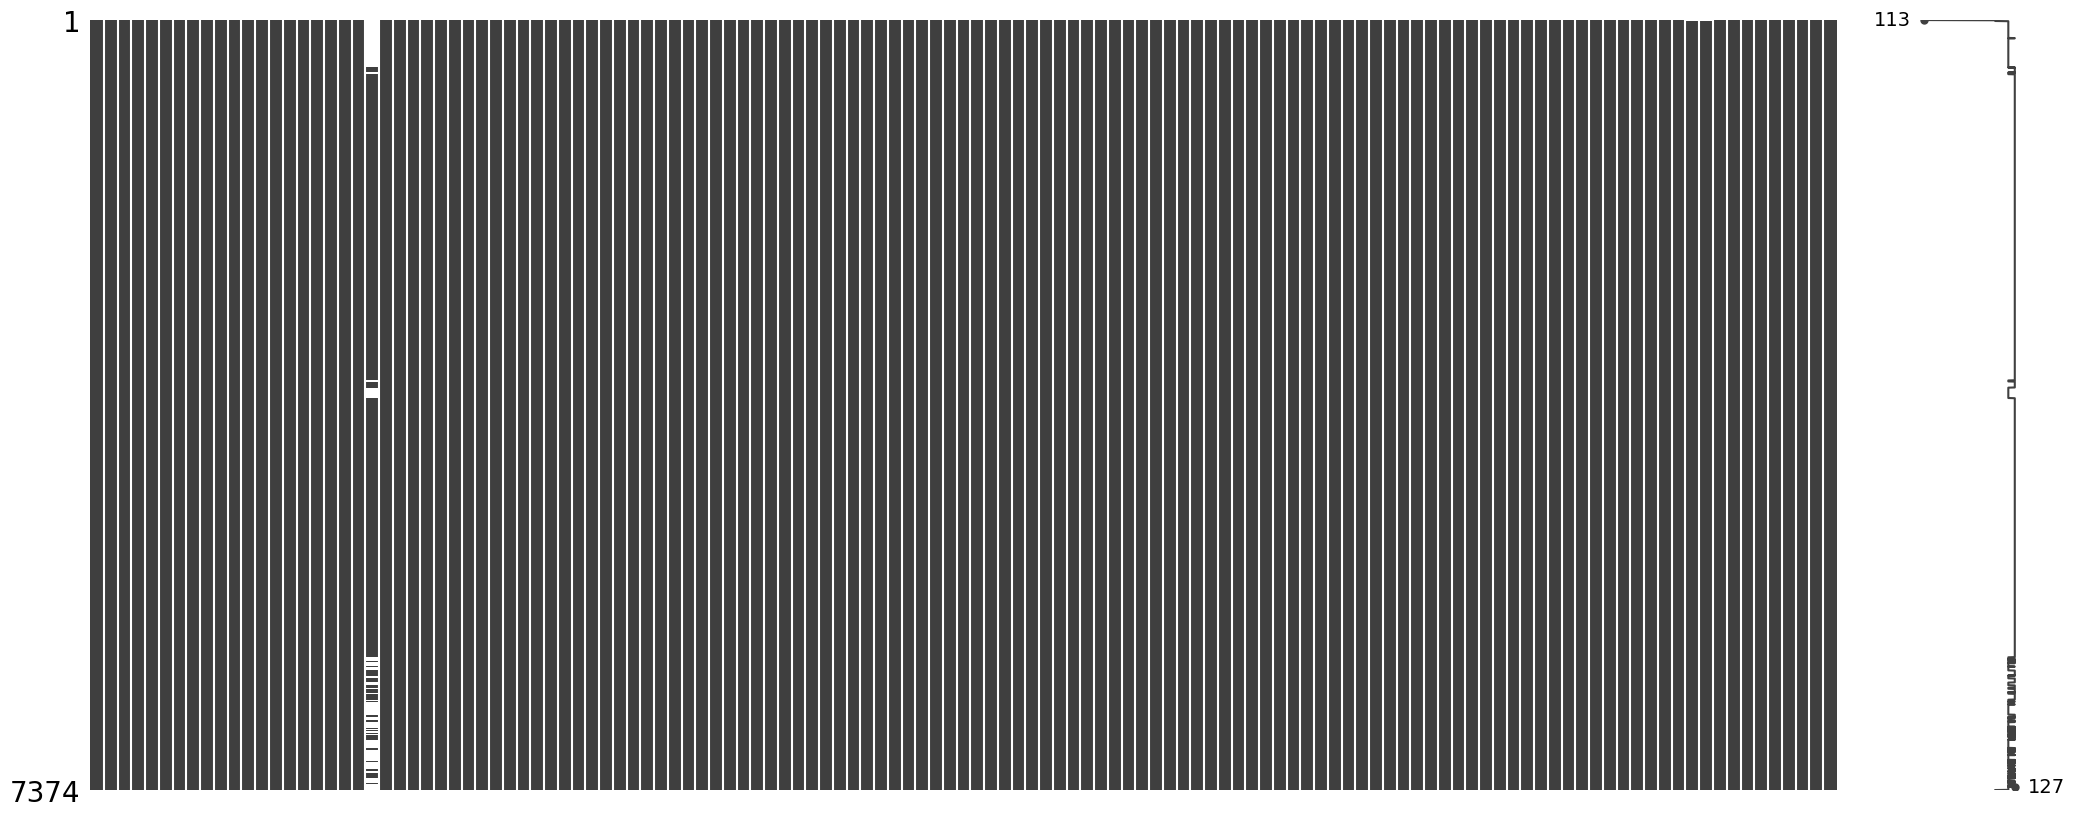

In [31]:
total_nan_count = nan_counts.sum()
print(f"\nTotal Missing Values in Dataset: {total_nan_count}")

import missingno as msno

# Visualize missing data
msno.matrix(df)

In [32]:
# Identify and drop columns with more than 50% null values
threshold = len(df) / 2

columns_with_many_nulls = nan_counts[nan_counts > threshold].index
#df = df.drop(columns=columns_with_many_nulls)
print(columns_with_many_nulls)

print("\nDataFrame after dropping columns with many null values:")
print(df.info())  # Re-check DataFrame info after cleaning

Index([], dtype='object')

DataFrame after dropping columns with many null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7374 entries, 0 to 7373
Columns: 127 entries, OSD.flyTime [s] to DETAILS.videoTime [s]
dtypes: bool(58), float64(53), int64(16)
memory usage: 4.3 MB
None


In [33]:
nan = df.isnull().sum()
print(nan)

OSD.flyTime [s]                     0
OSD.latitude                        0
OSD.longitude                       0
OSD.height [ft]                     0
OSD.heightMax [ft]                  0
                                   ..
DETAILS.maxHeight [ft]              0
DETAILS.maxHorizontalSpeed [MPH]    0
DETAILS.maxVerticalSpeed [MPH]      0
DETAILS.photoNum                    0
DETAILS.videoTime [s]               0
Length: 127, dtype: int64


In [34]:
nan.sum()

1424

In [35]:
# %% Impute remaining missing values
df = df.fillna(method='ffill').fillna(method='bfill')  # Forward fill, then backward fill
remaining_nulls = df.isnull().sum().sum()
print(f"\nRemaining Missing Values after Imputation: {remaining_nulls}")


Remaining Missing Values after Imputation: 0


C:\Users\HP\AppData\Local\Temp\ipykernel_8352\3212842861.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill').fillna(method='bfill')  # Forward fill, then backward fill


In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = data[selected_features + target_columns].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("UAV Trajectory Correlation Heatmap")
plt.show()

NameError: name 'data' is not defined

In [3]:
target_columns = [
    'OSD.latitude',
    'OSD.longitude',
    'OSD.altitude [ft]'
]

print("Target Variables:")
print(target_columns)

Target Variables:
['OSD.latitude', 'OSD.longitude', 'OSD.altitude [ft]']


In [4]:
selected_features = [
    'OSD.hSpeed [MPH]',
    'OSD.xSpeed [MPH]',
    'OSD.ySpeed [MPH]',
    'OSD.zSpeed [MPH]',
    'OSD.pitch',
    'OSD.roll',
    'OSD.yaw',
    'WEATHER.windSpeed [MPH]',
    'BATTERY.chargeLevel'
]

print(selected_features)

['OSD.hSpeed [MPH]', 'OSD.xSpeed [MPH]', 'OSD.ySpeed [MPH]', 'OSD.zSpeed [MPH]', 'OSD.pitch', 'OSD.roll', 'OSD.yaw', 'WEATHER.windSpeed [MPH]', 'BATTERY.chargeLevel']


In [7]:
corr = data[selected_features + target_columns].corr()

corr[target_columns]

NameError: name 'data' is not defined

In [9]:
import pandas as pd
data = pd.read_csv(r"C:\Users\HP\Desktop\DJIFlightRecord_2024-10-17_[13-51-44].csv")

C:\Users\HP\AppData\Local\Temp\ipykernel_21552\3742722392.py:2: DtypeWarning: Columns (41) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(r"C:\Users\HP\Desktop\DJIFlightRecord_2024-10-17_[13-51-44].csv")


In [10]:
corr = data[selected_features + target_columns].corr()

corr[target_columns]

,OSD.latitude,OSD.longitude,OSD.altitude [ft]
OSD.hSpeed [MPH],-0.267659,0.483360,0.718595
OSD.xSpeed [MPH],0.009167,-0.265122,0.009411
OSD.ySpeed [MPH],0.396579,-0.037968,0.005247
OSD.zSpeed [MPH],0.073079,-0.043701,-0.195422
OSD.pitch,0.255303,-0.413771,-0.539167
OSD.roll,0.100013,0.037528,0.086477
OSD.yaw,0.276958,0.070167,0.351535
WEATHER.windSpeed [MPH],0.219184,-0.119558,-0.158080
BATTERY.chargeLevel,0.167458,0.078358,0.330661
OSD.latitude,1.000000,-0.817637,-0.273919


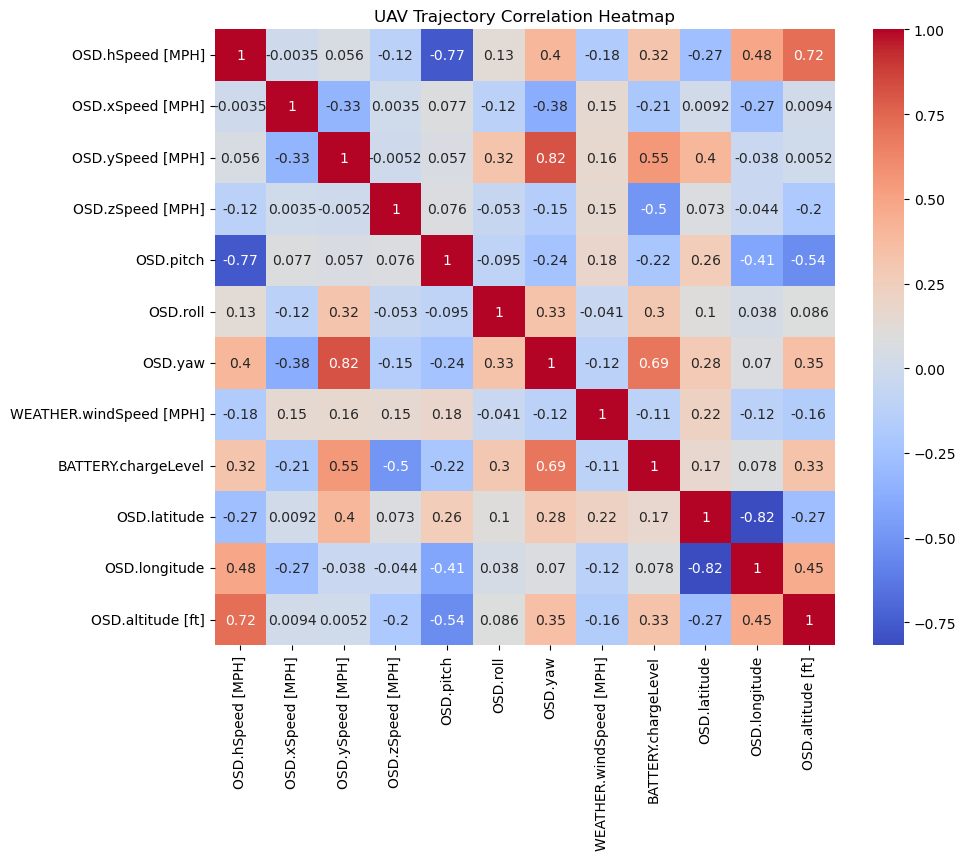

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = data[selected_features + target_columns].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("UAV Trajectory Correlation Heatmap")
plt.show()